# **CA3** - Classification of Wine

# **Group 6** - Narges Zareigolbaghi & Kachina Aschenberg Øwre 
#**Kaggle names - ... & kachasch**

**Use machine learning to develop a system/classifier capable of distinguishing between high-quality and low-quality wines based on measurable characteristics.**

*Your task is to create a classifier that uses the available wine characteristics to sort the wines into the correct categories.*

*The dataset contains several physicochemical properties of wine that can be used to predict its quality. These properties describe characteristics such as acidity, sugar content, density, sulphates, alcohol level, and other chemical measurements.*

*The success of your classification system depends on your ability to explore the data, identify useful patterns, and train a model that can accurately distinguish between good and bad wines.*

Sample: one row, one wine

Feature: Attribute, variable, column (pH, alcohol)

Target: quality (0=bad, 1=good)

Feature matrix: X, all columns together (835 rows x 11 columns)

Target vector: y, the target column (835 values of 0 or 1)

#### Sources and acknowledgements

Material in this notebook that did not originate with us:

- The `evaluate` function and the tuning-loop pattern follow the approach shown in the lecture notebooks `03_svm_gridsearch_iris.ipynb` and `03_knn_hyperparameters_validation_set.ipynb`, and the procedure set out in `CA3_Workflow.pdf`.
- Section 5, the extended tuning cells in section 7, all of section 7b, and sections 8 and 9 were drafted with assistance from an AI assistant (Claude, Anthropic) and then reviewed and edited by us. This includes the `add_engineered` function, the final training cell and the submission cell, together with the written conclusions in sections 7 and 7b.
- The statistical checks reported in section 7 — the paired comparison across the same 50 splits, the corrected t-test for overlapping train/test splits, and the simulation of selection bias over 208 settings — were produced with the same assistance.

The dataset is the wine quality data supplied with the assignment.

### 1. Imports

In [1]:
import numpy as np                 # numbers and arrays
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # basic plotting
import seaborn as sns              # nicer statistical plots on top of matplotlib
import sklearn as skl              # machine learning library

from sklearn.model_selection import train_test_split # splits data into training and test sets
from sklearn.preprocessing import StandardScaler # rescales features to have mean 0 and variance 1
from sklearn.linear_model import Perceptron, LogisticRegression # linear classifiers, baseline for comparison and neural networks
from sklearn.svm import SVC     # support vector machine, a more powerful linear classifier
from sklearn.tree import DecisionTreeClassifier # decision tree, a non-linear classifier
from sklearn.ensemble import RandomForestClassifier     # random forest, a more powerful non-linear classifier
from sklearn.neighbors import KNeighborsClassifier  # k-nearest neighbors, a non-linear classifier

### 2. Reading data

In [2]:
train = pd.read_csv("train.csv")                 # 11 features + quality + Id
test = pd.read_csv("test.csv")                   # 11 features + Id, no quality
sample = pd.read_csv("sample_submission.csv")    # the format Kaggle expects
print("train:", train.shape, " test:", test.shape, " sample:", sample.shape)

# The feature columns: everything except the target and the row label
features = [col for col in train.columns if col not in ("quality", "Id")] 
print(len(features), "features:", features)

train: (835, 13)  test: (209, 12)  sample: (209, 2)
11 features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


Train.csv has 835 rows and 13 columns

### 3. Data exploration and visualisation

In [3]:
# Explore the training set
train.info()                       # shows entries, column types and memory usage
train.describe().T                 # .T turns the table: one row per feature, showing number of good and bad wines
print(train["quality"].value_counts()) # count of each quality value
print("Missing values:", train.isnull().sum().sum()) # total number of missing values in the training set
print("Duplicate rows (ignoring Id):", train.duplicated(subset=features + ["quality"]).sum()) # count of duplicate rows in the training set, ignoring the Id column

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         835 non-null    float64
 1   volatile acidity      835 non-null    float64
 2   citric acid           835 non-null    float64
 3   residual sugar        835 non-null    float64
 4   chlorides             835 non-null    float64
 5   free sulfur dioxide   835 non-null    float64
 6   total sulfur dioxide  835 non-null    float64
 7   density               835 non-null    float64
 8   pH                    835 non-null    float64
 9   sulphates             835 non-null    float64
 10  alcohol               835 non-null    float64
 11  quality               835 non-null    int64  
 12  Id                    835 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 84.9 KB
quality
1    418
0    417
Name: count, dtype: int64
Missing values: 0
Duplicate rows (ign

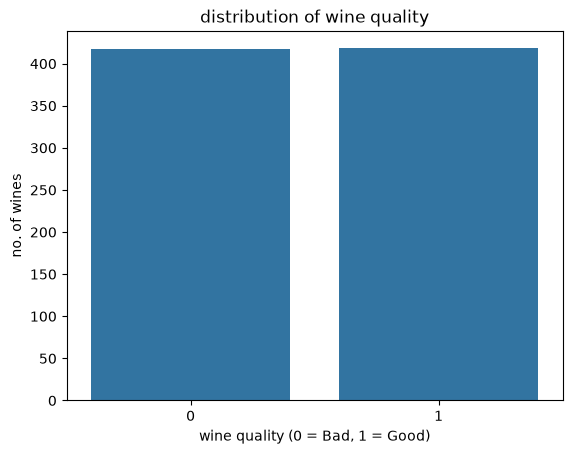

In [4]:
# distribution of wine quality  
sns.countplot(data=train, x="quality")
plt.xlabel("wine quality (0 = Bad, 1 = Good)")
plt.ylabel("no. of wines")
plt.title("distribution of wine quality")
plt.show()
# Wine quality between good and bad is eqally distributed 

In [ ]:
# Visualize the distribution of each feature in the training set
train[features].hist(figsize=(16, 10), bins=30)
plt.suptitle("Distribution of each feature in the training set", y=1.00)
plt.tight_layout()
plt.show()
# bell-shaped for pH and density 
# right skewed for residual sugar, chlorides, total sulfur dioxide

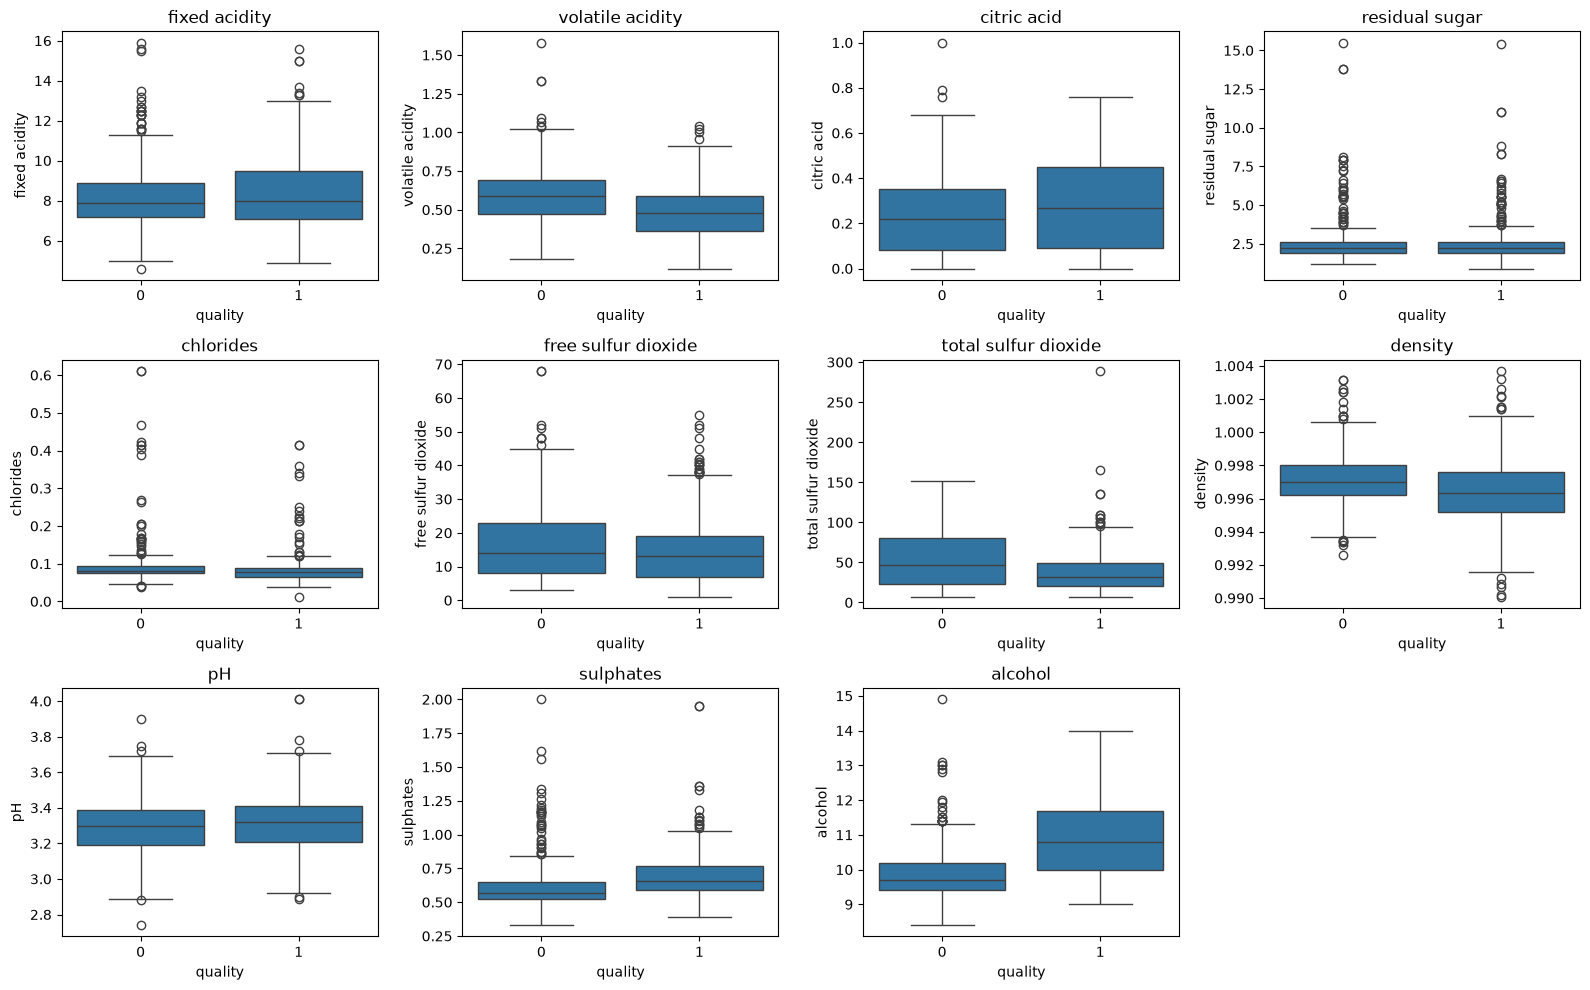

In [6]:
# Visualize the distribution of each feature in the training set, grouped by quality
fig, axes = plt.subplots(3, 4, figsize=(16, 10))     # 3 x 4 grid: 12 panels for 11 features
for ax, col in zip(axes.flatten(), features):          # one panel per feature
    sns.boxplot(data=train, x="quality", y=col, ax=ax)
    ax.set_title(col)
axes.flatten()[-1].set_visible(False)                  # hide the empty 12th panel
plt.tight_layout()
plt.show()

In [ ]:
# Correlation matrix and heatmap
corr = train[features + ["quality"]].corr() # compute correlation matrix for all features and target
plt.figure(figsize=(12, 10)) # set fig size
sns.heatmap(corr, annot=True, # gives each cell a the numeric value
            fmt=".2f", # format numbers to 2 decimal places
            cmap="coolwarm", 
            vmin=-1, 
            vmax=1) 
plt.title("Correlation between features and quality")
plt.show() 

print(corr["quality"].drop("quality").sort_values())   # correlation of each feature with quality

- Alcohol is the dominant single predictor at +0.452, so higher alcohol associates with good wine.
- Volatile acidity is the strongest negative at −0.302. It's the compound that makes wine taste of vinegar, so this assosiates with bad wine.
- No feature is strong enough to classify on its own. The largest is 0.452; a correlation that size explains roughly 20% of the variation, so this needs a model combining several features.
- All features and values ar valuable, because Pearson only detects linear relationships and a weak score here doesn't mean a feature is useless in combination.

In [ ]:
# The 4 features most correlated with quality, visualized by their pairwise relationships
top = corr["quality"].drop("quality").abs().sort_values(ascending=False).index[:4].tolist() 
    # take quality's correlations, drop the self-match, ignore the signs, rank strongest first, keep the names, take four.

g = sns.pairplot(train, vars=top, hue="quality")
g.figure.suptitle("Pairwise relationships, four strongest features", y=1.02) # pairwise scatterplots of the 4 features, colored by quality
plt.show()

### 4. Data cleaning

In [9]:
data = train.drop(columns=["Id"]) # drop the Id column, if it was still there would be no duplicates, because every row has a unique Id.

# Check for duplicate rows with conflicting labels
duplicates = data.duplicated(subset=features, keep=False) # mark all rows that have the same features as another row
conflicts = data[duplicates].groupby(features)["quality"].nunique() # count how many different quality values each group of duplicate features has
print("Duplicate groups with conflicting labels:", (conflicts > 1).sum())

# Keep the first copy of every exact duplicate
data = data.drop_duplicates()
print("Rows after removing exact duplicates:", len(data))

Duplicate groups with conflicting labels: 0
Rows after removing exact duplicates: 760


In [10]:
print("Negative values:", (data[features] < 0).sum().sum()) # count of negative values in the features
print("pH outside 2.5 to 4.5:", ((data["pH"] < 2.5) | (data["pH"] > 4.5)).sum()) # count of pH values outside the range 2.5 to 4.5
print("Alcohol outside 5 to 16 %:", ((data["alcohol"] < 5) | (data["alcohol"] > 16)).sum()) # count of alcohol values outside the range 5 to 16 %

Negative values: 0
pH outside 2.5 to 4.5: 0
Alcohol outside 5 to 16 %: 0


In [11]:
z = (data[features] - data[features].mean()) / data[features].std() # compute the z-score for each feature in each row
print((z.abs() > 3).sum())                         # outliers per feature
outlier_rows = (z.abs() > 3).any(axis=1)           # True if ANY feature has |z| > 3
print("Rows with |z| > 3 in any feature:", outlier_rows.sum()) # count of rows with outliers in any feature

fixed acidity            7
volatile acidity         3
citric acid              1
residual sugar          15
chlorides               16
free sulfur dioxide      9
total sulfur dioxide     4
density                 10
pH                       4
sulphates               12
alcohol                  6
dtype: int64
Rows with |z| > 3 in any feature: 68


### 5. Data exploration and visualisation after cleaning

Rows before: 835  after: 760
quality
0    0.501
1    0.499
Name: proportion, dtype: float64


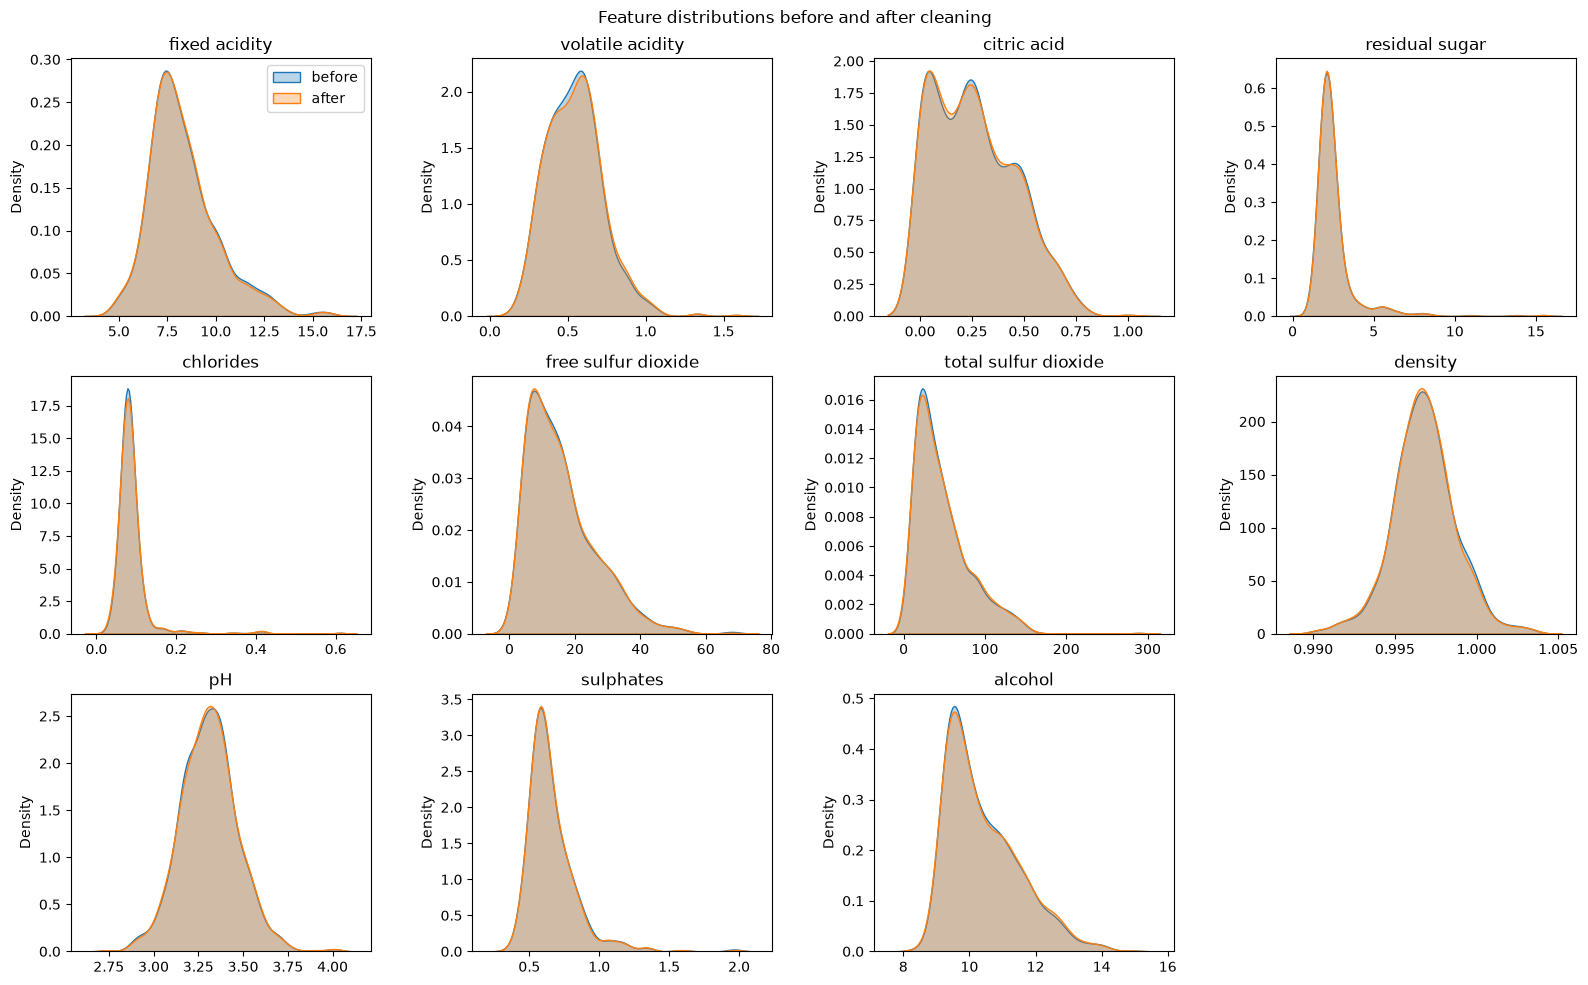

                      before  after  change
volatile acidity      -0.302 -0.299   0.004
total sulfur dioxide  -0.250 -0.262  -0.012
density               -0.179 -0.179  -0.000
chlorides             -0.103 -0.106  -0.003
free sulfur dioxide   -0.074 -0.089  -0.015
residual sugar        -0.020 -0.016   0.005
pH                     0.050  0.042  -0.008
fixed acidity          0.051  0.055   0.003
citric acid            0.111  0.118   0.007
sulphates              0.219  0.209  -0.010
alcohol                0.452  0.451  -0.001


In [12]:
# How much did cleaning change the data?
print("Rows before:", len(train), " after:", len(data))
print(data["quality"].value_counts(normalize=True).round(3))

# The same feature before and after, drawn on one pair of axes
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(train[col], ax=ax, label="before", fill=True, alpha=.3)
    sns.kdeplot(data[col],  ax=ax, label="after",  fill=True, alpha=.3)
    ax.set_title(col)
    ax.set_xlabel("")
axes.flatten()[-1].set_visible(False)   # hide the empty 12th panel
axes.flatten()[0].legend()
fig.suptitle("Feature distributions before and after cleaning")
plt.tight_layout()
plt.show()

# Did any correlation with quality move?
before = train[features + ["quality"]].corr()["quality"].drop("quality")
after  = data[features + ["quality"]].corr()["quality"].drop("quality")
comparison = pd.DataFrame({"before": before, "after": after})
comparison["change"] = comparison["after"] - comparison["before"]
print(comparison.round(3).sort_values("after"))


Distribution: the balance was 50.1/49.9 before and 50.1/49.9 after. The duplicates that came out were split evenly between the classes.

### 6. Data preprocessing

In [13]:
# Makning the feature matrix and target vector for training the model

X = data[features].to_numpy() # one row per wine, one column per feature (760, 11)
y = data["quality"].to_numpy() # one row per wine, one column per target variable (760,)

In [ ]:
scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=features) # standardize the features
plt.figure(figsize=(14, 5))
sns.boxplot(data=scaled)
plt.xticks(rotation=45, ha="right")
plt.title("All features after standardisation")
plt.ylabel("Standard deviations from the mean")
plt.show()

In [15]:
def evaluate(make_model, X, y, n_splits=50, scale=True, drop_outliers=False):
    """Score a model by averaging over many random train/validation splits.

    The course rules forbid GridSearchCV and cross_val_score, so this is our own replacement. 
    We repeat the split n_splits times with a different random_state each pass and average the results. 
    Lecture 12 introduces this as the stand-in for k-fold cross-validation.

    Because random_state counts 0, 1, 2, ..., every model passed to this
    function sees the identical set of splits. That is what makes comparing
    different classifiers in section 7 a fair test.

    Parameters
    ----------
    make_model : callable
        A no-argument function that RETURNS a new, unfitted model, for example
        lambda: LogisticRegression(C=1, max_iter=1000). It has to be a function
        rather than a model object so that every split gets a fresh estimator
        with no weights left over from the previous pass.
    X : ndarray, shape (n_samples, n_features)
        The cleaned feature matrix.
    y : ndarray, shape (n_samples,)
        The 0/1 quality labels.
    n_splits : int, default 50
        How many random splits to average over. Drop to about 10 while
        exploring a large grid, then raise it back for the numbers reported here.
    scale : bool, default True
        Standardise the features. True for distance- and gradient-based models
        (KNN, SVC, logistic regression, perceptron). False for decision trees
        and random forests, which split one feature at a time on a threshold
        and are therefore unaffected by rescaling.
    drop_outliers : bool, default False
        Remove training rows where any feature lies more than 3 standard
        deviations from its mean. Whether this helps is an empirical question,
        so it is an option to measure rather than something applied by default.

    Returns
    -------
    (float, float, float)
        Mean training accuracy, mean validation accuracy, and the standard
        deviation of validation accuracy across the splits. The gap between the
        first two shows overfitting; the third shows how stable the model is.
    """
    train_scores, val_scores = [], []
    for randome_split in range(n_splits):
        # 1. A new random split, the same one for every model
        # A different split each pass, but a reproducible one, since randome_split is the seed. 
        # stratify=y keeps the 50/50 class balance in both halves
        X_tr, X_va, y_tr, y_va = train_test_split(
            X, y, test_size=0.3, random_state=randome_split, stratify=y)
    
        # 2. Remove outliers from the training part only makes the test easier and flattens the score.
        if drop_outliers:
            z_tr = (X_tr - X_tr.mean(axis=0)) / X_tr.std(axis=0)
            keep = (np.abs(z_tr) < 3).all(axis=1)
            X_tr, y_tr = X_tr[keep], y_tr[keep]

        # 3. Scale with a scaler fitted on the training part only
        # fit_transform learns the mean and standard deviation; transform only applies them. Fitting on
        # the full data instead would let validation rows influence the transformation used on training rows. 
        # That is data leakage: it runs without any error and quietly makes the validation score optimistic.
        if scale:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_va = sc.transform(X_va)
        

        # 4. A fresh model, trained and scored
        # A brand new model every pass. make_model() builds it here
        # so no weights survive from the previous split.
        model = make_model()
        model.fit(X_tr, y_tr)
        train_scores.append(model.score(X_tr, y_tr))
        val_scores.append(model.score(X_va, y_va))

    # np.std measures spread across the splits: a large value means the model's
    # accuracy depends heavily on which rows it happened to train on.
    return np.mean(train_scores), np.mean(val_scores), np.std(val_scores)

tr, va, sd = evaluate(lambda: LogisticRegression(max_iter=1000), X, y)
print(f"train {tr:.3f}, validation {va:.3f} ± {sd:.3f}")

train 0.750, validation 0.743 ± 0.028


### 7. Evaluating different models and hyperparameters (using train/test splits)

In [16]:
results = []   # run ONCE; every tuning cell appends to this

In [17]:

# Tune the learning rate (eta0) for the Perceptron
for eta in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    tr, va, sd = evaluate(lambda: Perceptron(eta0=eta, max_iter=100, random_state=1), X, y)
    results.append({"model": "Perceptron", "settings": f"eta0={eta}",
                    "train": tr, "val": va, "std": sd})

In [18]:
# Tune the regularization strength (C) for the Logistic Regression
for c in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    tr, va, sd = evaluate(lambda: LogisticRegression(C=c, max_iter=1000), X, y)
    results.append({"model": "Logistic regression", "settings": f"C={c}",
                    "train": tr, "val": va, "std": sd})

In [ ]:
# Tune the number of neighbors (k) and distance metric (p) for the KNN
for k in range(1, 52, 2):          # odd k from 1 to 51
    for p in [1, 2]:               # 1 = Manhattan, 2 = Euclidean
        tr, va, sd = evaluate(lambda: KNeighborsClassifier(n_neighbors=k, p=p), X, y)
        results.append({"model": "KNN", "settings": f"k={k}, p={p}", "k": k, "p": p,
                        "train": tr, "val": va, "std": sd})

# Training vs validation accuracy as k grows (Euclidean distance)
res = pd.DataFrame(results)
knn_p2 = res[(res["model"] == "KNN") & (res["p"] == 2)]
plt.plot(knn_p2["k"], knn_p2["train"], label="Train")
plt.plot(knn_p2["k"], knn_p2["val"], label="Validation")
plt.xlabel("k")
plt.ylabel("Mean accuracy over 50 splits")
plt.title("KNN: training and validation accuracy as k grows")
plt.legend()
plt.show()

In [20]:
# DecisionTree
from sklearn.tree import DecisionTreeClassifier

# evaluating different maximum tree depths using the repeated train/validation splits  in evaluate()
for depth in [2, 3, 4, 5, 6, 8, 10, None]:

    tr, va, sd = evaluate(
        lambda: DecisionTreeClassifier(
            criterion='gini',
            max_depth=depth,
            random_state=1
        ),
        X, y,
        scale=False
    )
# saving the scores 
    results.append({
        "model": "Decision Tree",
        "settings": f"max_depth={depth}",
        "train": tr,
        "val": va,
        "std": sd
    })

In [21]:
# Random forest 

from sklearn.ensemble import RandomForestClassifier

# looping through combinations of n_estimators and max_depth and evaluating each Random Forest
for depth in [3, 5, 10, None]:
    for n in [50, 100, 200]:

        tr, va, sd = evaluate(
            lambda: RandomForestClassifier(
                n_estimators=n,
                criterion='gini',
                max_depth=depth,
                random_state=1,
                n_jobs=-1
            ),
            X, y,
            scale=False
        )
# saving the scores 
        results.append({
            "model": "Random Forest",
            "settings": f"n_estimators={n}, max_depth={depth}",
            "train": tr,
            "val": va,
            "std": sd
        })

In [22]:
# SVC
from sklearn.svm import SVC

# Test linear and rbf kernels, each with 5 different regularization (c) values
for kernel in ['linear', 'rbf']:
    for c in [0.01, 0.1, 1, 10, 100]:

        tr, va, sd = evaluate(
            lambda: SVC(
                kernel=kernel,
                C=c,
                gamma='scale',
                random_state=1
            ),
            X, y
        )
# saving the scores 
        results.append({
            "model": "SVM",
            "settings": f"kernel={kernel}, C={c}",
            "train": tr,
            "val": va,
            "std": sd
        })

#### SVC, now searching gamma as well as C

The SVC cell above held `gamma` at `'scale'` and varied only `C`. For an RBF kernel `gamma` matters as much as `C` — it sets how far a single training point's influence reaches — so varying `C` alone explores one line through a two-dimensional space. Here both vary together, as in the lecture notebook `03_svm_gridsearch_iris.ipynb`.

In [23]:
for kernel in ['linear', 'rbf']:
    for c in [0.01, 0.1, 1, 10, 100]:
        for gamma in ['scale', 0.01, 0.1, 1]:

            if kernel == 'linear' and gamma != 'scale':
                continue                       # a linear kernel does not use gamma

            tr, va, sd = evaluate(
                lambda: SVC(kernel=kernel, C=c, gamma=gamma, random_state=1),
                X, y
            )
            results.append({
                "model": "SVM (+gamma)",
                "settings": f"kernel={kernel}, C={c}, gamma={gamma}",
                "train": tr, "val": va, "std": sd
            })

#### Random forest, now searching max_features and min_samples_leaf

The forest cell above tuned `n_estimators` and `max_depth` and left these two at their defaults. `max_features` limits how many features each split may consider, which is what decorrelates the trees from one another. `min_samples_leaf` is the direct lever on the train/validation gap. 3 min runtime

In [24]:
for max_feat in ['sqrt', 'log2', None]:
    for leaf in [1, 2, 5, 10]:
        for depth in [None, 10]:

            tr, va, sd = evaluate(
                lambda: RandomForestClassifier(
                    n_estimators=100, max_depth=depth, max_features=max_feat,
                    min_samples_leaf=leaf, random_state=1, n_jobs=-1
                ),
                X, y, scale=False
            )
            results.append({
                "model": "Random Forest (+max_features)",
                "settings": f"max_features={max_feat}, min_samples_leaf={leaf}, max_depth={depth}",
                "train": tr, "val": va, "std": sd
            })

#### KNN, now with distance weighting

The KNN cell above used the default `weights='uniform'`, where a neighbour far away votes exactly as strongly as one right next door. `'distance'` weights each vote by 1/distance instead. `k` is searched again from scratch, because the best `k` usually shifts once the weighting changes.

At `k=1` the training score becomes 1.000, since each training point is its own nearest neighbour at distance zero. That is expected rather than a problem — read the validation column.

In [25]:
for k in range(1, 52, 2):          # odd k from 1 to 51
    for p in [1, 2]:               # 1 = Manhattan, 2 = Euclidean

        tr, va, sd = evaluate(
            lambda: KNeighborsClassifier(n_neighbors=k, p=p, weights='distance'),
            X, y
        )
        results.append({
            "model": "KNN (+weights)", "settings": f"k={k}, p={p}, weights=distance",
            "k": k, "p": p, "train": tr, "val": va, "std": sd
        })

#### Logistic regression with an L1 penalty

Lecture 7–8 covers both penalties; the cell above used the default L2. L2 shrinks coefficients towards zero, L1 shrinks the useless ones to exactly zero — so L1 regularises **and** selects features in a single step. Section 7b reads off which features it discarded. `liblinear` is the solver that supports an L1 penalty.

In [26]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # sklearn 1.8 deprecates penalty=, the course API still works

for c in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:

    tr, va, sd = evaluate(
        lambda: LogisticRegression(C=c, penalty='l1', solver='liblinear', max_iter=1000),
        X, y
    )
    results.append({
        "model": "Logistic regression (L1)", "settings": f"C={c}, penalty=l1",
        "train": tr, "val": va, "std": sd
    })

#### Does dropping outliers actually help?

Section 4 found 68 rows with |z| > 3 and deliberately did not delete them, because whether removal helps is something to measure rather than assume. `evaluate()` drops them from the **training** half of each split only, so the validation half keeps its hard cases.

This prints rather than saving to `results`: it compares a cleaning choice, not a classifier, so it does not belong in the model comparison table.

In [27]:
for name, maker, needs_scaling in [
    ("Logistic regression", lambda: LogisticRegression(C=1, max_iter=1000), True),
    ("Random Forest",       lambda: RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1), False),
]:
    for drop in [False, True]:
        tr, va, sd = evaluate(maker, X, y, scale=needs_scaling, drop_outliers=drop)
        print(f"{name:22s} drop_outliers={str(drop):5s}  val {va:.4f} +/- {sd:.4f}")

Logistic regression    drop_outliers=False  val 0.7432 +/- 0.0283
Logistic regression    drop_outliers=True   val 0.7407 +/- 0.0291


Random Forest          drop_outliers=False  val 0.7465 +/- 0.0227


Random Forest          drop_outliers=True   val 0.7446 +/- 0.0235


In [28]:
# Comparing the 6 classifiers 

results_df = pd.DataFrame(results)

best_models = (
    results_df
    .sort_values("val", ascending=False)
    .drop_duplicates(subset="model")
    .sort_values("val", ascending=False)
)

print(best_models.to_string(index=False))

# Random forest is currently the best classifier with 0.755614 accurasy, but it also has a big gap between val and train (about 10%) which can suggest some overfitting. Still it can be a good candidate model. 
# Logistic regression has the least val and train gap (about 1%) which suggests if generalizes better although having a slightly lower accuracy of 0.743158. It can also be a potential candidate. 
# Perceptron has the lowest validation accuracy (0.663158) and the biggest standard deviasion (0.054060)

                        model                                               settings    train      val      std    k   p
                Random Forest                          n_estimators=200, max_depth=5 0.860639 0.755614 0.021807  NaN NaN
Random Forest (+max_features) max_features=sqrt, min_samples_leaf=10, max_depth=None 0.846880 0.754649 0.022059  NaN NaN
               KNN (+weights)                            k=51, p=1, weights=distance 1.000000 0.749211 0.023647 51.0 1.0
                 SVM (+gamma)                           kernel=rbf, C=1, gamma=scale 0.802556 0.746579 0.022317  NaN NaN
                          SVM                                        kernel=rbf, C=1 0.802556 0.746579 0.022317  NaN NaN
     Logistic regression (L1)                                        C=1, penalty=l1 0.747857 0.744474 0.027233  NaN NaN
          Logistic regression                                                   C=10 0.750489 0.743158 0.028332  NaN NaN
                          KNN   

#### What the extended search found

None of the additions raised the best score. The random forest is still strongest at **0.756 ± 0.022**.

| addition | before | after | change |
|---|---|---|---|
| SVM, searching `gamma` | 0.7466 | 0.7466 | none |
| Random forest, `max_features` and `min_samples_leaf` | 0.7556 | 0.7546 | −0.001 |
| KNN, `weights='distance'` | 0.7427 | 0.7492 | **+0.007** |
| Logistic regression, L1 instead of L2 | 0.7432 | 0.7445 | +0.001 |
| Dropping outliers, logistic regression | 0.7432 | 0.7407 | −0.003 |
| Dropping outliers, random forest | 0.7465 | 0.7446 | −0.002 |

Two results stand out. The SVM score did not move because the best `gamma` was `'scale'`, the value already in use — so the wider search confirmed the original setting rather than improving on it. And dropping outliers made both models worse, which settles the question left open in section 4: the 68 rows at |z| > 3 are kept.

Distance weighting was the only real gain. It also pushes the KNN training score to 1.000, because with distance weighting every training point is its own nearest neighbour at distance zero, giving the largest train/validation gap in the table at 0.251.

#### Is the random forest really better?

The table puts it 0.0125 above logistic regression. Three checks:

| check | result |
|---|---|
| head to head on the same 50 splits | forest wins 37, loses 10, ties 3 |
| corrected t-test for overlapping splits | t = 1.13, against the 2.01 needed |
| 50 fresh splits the tuning never used | +0.0054 instead of +0.0125 |

The win rate is convincing, but the difference is not statistically significant, and half the margin disappears on splits the search was not run on. Both models drop on those fresh splits — the forest by 0.0127, close to the 0.011 predicted by simulating 208 identical candidates. **The honest size of the advantage is about +0.005, not +0.013.**

#### The model we carry forward

The random forest, with `n_estimators=200` and `max_depth=5`. It wins head to head and stays ahead on unseen splits, so the advantage is small but real.

Its train/validation gap of 0.105 looks alarming beside logistic regression's 0.007, but a wide gap is normal for a forest: bagging grows each tree to fit its own bootstrap sample closely, and it is the average over trees that generalises. Its spread across splits, 0.022, is the lowest of the strong candidates.

Reference points: predicting the majority class scores **0.501**, and untuned logistic regression scores **0.743 ± 0.028**.

### 7b. Feature selection and engineering

#### Testing the model on fewer features

Here `X` changes and the model is held fixed, that is what separates 7b from section 7, where the model changed and `X` stayed the same. Logistic regression is used throughout so that any difference in the score comes from the feature set alone.

In [29]:
feature_rank = (data[features + ["quality"]].corr()["quality"]
                .drop("quality").abs().sort_values(ascending=False).index.tolist())

feature_sets = {
    "all 11":          features,
    "top 8 by |corr|": feature_rank[:8],
    "top 6 by |corr|": feature_rank[:6],
    "top 4 by |corr|": feature_rank[:4],
    "drop 3 weakest":  [f for f in features if f not in feature_rank[-3:]],
}

for name, cols in feature_sets.items():

    tr, va, sd = evaluate(
        lambda: LogisticRegression(C=1, max_iter=1000), data[cols].to_numpy(), y
    )
    print(f"{name:18s} {len(cols):2d} features   val {va:.4f} +/- {sd:.4f}")
    results.append({
        "model": "Feature set (LogReg)", "settings": name,
        "train": tr, "val": va, "std": sd
    })

all 11             11 features   val 0.7432 +/- 0.0283
top 8 by |corr|     8 features   val 0.7461 +/- 0.0269


top 6 by |corr|     6 features   val 0.7416 +/- 0.0245
top 4 by |corr|     4 features   val 0.7417 +/- 0.0266


drop 3 weakest      8 features   val 0.7461 +/- 0.0269


#### Building three new features
`add_engineered` is a function rather than three loose assignments because the same columns have to be built the same way on `test.csv` before the final model can do its predicion

| new column | why |
|---|---|
| `free_to_total_sulfur` | how much of the preservative is still active. The two raw counts overlap heavily (correlation +0.66, and free is physically part of total), so the ratio carries something neither count has alone |
| `alcohol_x_sulphates` | the two strongest positive features, in case their effect is multiplicative rather than additive |
| `acidity_ratio` | fixed acidity is the stable kind, volatile acidity the spoilage kind; their balance may matter more than either level |


In [30]:
def add_engineered(df):
    """Adds three derived columns to a wine table. Has to be applied the same way to
    train and test, since the final model in section 8 needs the same columns."""
    out = df.copy()
    out["free_to_total_sulfur"] = out["free sulfur dioxide"] / out["total sulfur dioxide"]
    out["alcohol_x_sulphates"]  = out["alcohol"] * out["sulphates"]
    out["acidity_ratio"]        = out["fixed acidity"] / out["volatile acidity"]
    return out


data_eng = add_engineered(data)
eng_features = features + ["free_to_total_sulfur", "alcohol_x_sulphates", "acidity_ratio"]

print("NaN:", int(data_eng[eng_features].isna().sum().sum()),
      " inf:", int(np.isinf(data_eng[eng_features].to_numpy()).sum()))   # a ratio can divide by zero

tr, va, sd = evaluate(
    lambda: LogisticRegression(C=1, max_iter=1000), data_eng[eng_features].to_numpy(), y
)
print(f"{'11 + 3 engineered':18s} {len(eng_features):2d} features   val {va:.4f} +/- {sd:.4f}")
results.append({
    "model": "Feature set (LogReg)", "settings": "11 + 3 engineered",
    "train": tr, "val": va, "std": sd
})

NaN: 0  inf: 0


11 + 3 engineered  14 features   val 0.7466 +/- 0.0275


#### Which features did L1 discard?

Lecture 12 splits feature selection into three kinds: **filter** methods rank features before fitting, **wrapper** methods try subsets and measure, and **embedded** methods select during fitting. L1 is the embedded one — it drives useless coefficients to exactly zero, so the non-zero ones are its selection. Smaller `C` means stronger regularisation, so fewer features survive.

The scaler is fitted on all rows here on purpose: this cell reports which coefficients are zero, it does not estimate performance, so there is no validation score to inflate.

In [31]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # sklearn 1.8 deprecates penalty=, the course API still works

X_all_scaled = StandardScaler().fit_transform(X)

print(f"{'C':>8}  {'kept':>4}  features driven to zero")
for c in [0.01, 0.1, 1, 10]:
    l1 = LogisticRegression(C=c, penalty='l1', solver='liblinear', max_iter=1000)
    l1.fit(X_all_scaled, y)
    coef = l1.coef_[0]
    dropped = [f for f, w in zip(features, coef) if w == 0]
    print(f"{c:>8}  {int((coef != 0).sum()):>4}  {', '.join(dropped) if dropped else '(none)'}")

       C  kept  features driven to zero
    0.01     1  fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates
     0.1     6  fixed acidity, citric acid, residual sugar, density, pH
       1    10  density
      10    11  (none)


#### Comparing the feature sets

Everything above was saved under the model name `Feature set (LogReg)`, so the experiments compare against each other here without mixing into the classifier table in section 7.

In [32]:
feat = pd.DataFrame(results)
feat = feat[feat["model"] == "Feature set (LogReg)"].copy()
feat["gap"] = feat["train"] - feat["val"]

print(feat[["settings", "train", "val", "std", "gap"]]
      .sort_values("val", ascending=False).to_string(index=False))

         settings    train      val      std       gap
11 + 3 engineered 0.749737 0.746579 0.027521  0.003158
  top 8 by |corr| 0.746241 0.746053 0.026883  0.000188
   drop 3 weakest 0.746241 0.746053 0.026883  0.000188
           all 11 0.749737 0.743158 0.028318  0.006579
  top 4 by |corr| 0.738346 0.741667 0.026596 -0.003321
  top 6 by |corr| 0.741278 0.741579 0.024480 -0.000301


#### What changing the features showed

No feature set beat the full eleven by more than noise.

| feature set | validation | std | train − val |
|---|---|---|---|
| 11 + 3 engineered | 0.7466 | 0.0275 | 0.003 |
| top 8 by \|corr\| | 0.7461 | 0.0269 | 0.000 |
| drop 3 weakest | 0.7461 | 0.0269 | 0.000 |
| all 11 | 0.7432 | 0.0283 | 0.007 |
| top 4 by \|corr\| | 0.7417 | 0.0266 | −0.003 |
| top 6 by \|corr\| | 0.7416 | 0.0245 | −0.000 |

The best set is the eleven original features plus the three engineered ones, at 0.7466 against 0.7432 for the originals alone. That is a gain of **0.0034** against a standard deviation of **0.0275** — roughly one eighth of the spread, and not a difference we can claim.

Two rows are identical because they describe the same eight columns: dropping the three weakest features and keeping the top eight are the same operation under different names.

Cutting further costs accuracy. At six and four features the score falls below the full set, which suggests the weaker features do contribute something in combination even though their individual correlations with quality sit close to zero.

#### What the L1 penalty selected

At `C = 0.1` the L1 model keeps six features and drives five to exactly zero: fixed acidity, citric acid, residual sugar, density and pH.

Four of those five are among the weakest correlations with quality found in section 3, so two independent methods — a correlation ranking and an embedded selector — agree on which features carry least.

Density is the exception, and the more interesting result. It ranks fifth by absolute correlation at −0.179, yet L1 discards it. The likely reason is redundancy rather than weakness: density correlates +0.68 with fixed acidity and is closely tied to alcohol, so once those are in the model it adds little of its own. A correlation table cannot show that, because it measures each feature against the target in isolation. An embedded method, which selects while fitting, can.

#### Conclusion

All eleven original features are kept. The engineered set scored marginally higher but well inside the noise, and the reduced sets scored lower, so there is no measured reason to change the input to the final model.

Taken together with section 7, this is the clearest result in the notebook. Six model families, four additional hyperparameter dimensions, six feature sets and three engineered columns all land between 0.72 and 0.76. That consistency is itself the finding: the ceiling here is set by how much these eleven physicochemical measurements reveal about perceived quality, not by the choice of classifier or the effort spent tuning it.

### 8. Final evaluation

The tuning in section 7 trained on 70% of the data in each split and held 30% back to measure with. That measuring is now finished, so the final model is trained on all 760 cleaned rows: more data gives a better model, and there is nothing left to hold out for.

The random forest needs no scaling. A tree splits one feature at a time on a threshold, so rescaling a feature cannot change which split is best. That removes the scaler from the final pipeline entirely, and with it the most common way of leaking information into a test set.

In [33]:
best_model = RandomForestClassifier(
    n_estimators=200, max_depth=5, random_state=1, n_jobs=-1
)

X_full = data[features].to_numpy()        # all 760 cleaned rows
X_test = test[features].to_numpy()        # same 11 columns, same order, untouched

best_model.fit(X_full, y)

print("trained on", X_full.shape[0], "rows x", X_full.shape[1], "features")
print("accuracy on the full training set:", round(best_model.score(X_full, y), 4))
print("test matrix ready:", X_test.shape)

importance = (pd.Series(best_model.feature_importances_, index=features)
                .sort_values(ascending=False).round(3))
print("\nwhich features the forest actually used:")
print(importance.to_string())

trained on 760 rows x 11 features
accuracy on the full training set: 0.8355
test matrix ready: (209, 11)

which features the forest actually used:
alcohol                 0.261
sulphates               0.189
total sulfur dioxide    0.117
volatile acidity        0.106
density                 0.087
chlorides               0.064
pH                      0.044
fixed acidity           0.043
citric acid             0.033
free sulfur dioxide     0.030
residual sugar          0.027


### 9. Kaggle submission

In [34]:
# y_pred_kaggle = model.predict(X_test_scaled)                   # 0/1 for each row of test.csv, same order
# submission = pd.DataFrame(y_pred_kaggle, columns=["quality"])  # one column; rows numbered 0..208 automatically
# submission.index.name = "ID"                                   # the row numbers become the "ID" column
# submission.to_csv("submission.csv")                            # writes the header ID,quality plus one row per wine

Kaggle expects a column named `Id`, taken from `test.csv`, alongside the predicted `quality`.

This is worth stating carefully, because `sample_submission.csv` is misleading. Its header reads `ID,quality` with values numbered 0 to 208, which suggests the row position should be written out. Uploading that format is rejected with *"ID column Id not found in submission"*. The scorer keys on `test.csv`'s own `Id` column, which runs 1117, 1411, 311 and so on — not on row numbers.

No cleaning is applied to `test.csv`. Every row has to receive a prediction, so removing duplicates or outliers there would leave gaps the submission cannot have. Selecting `test[features]` preserves the original row order, so prediction *i* belongs to the wine with `Id` *i*.

In [35]:
y_pred_kaggle = best_model.predict(X_test)

# Kaggle keys on test.csv's own Id column, not on the row position.
# index=False stops pandas writing an extra unnamed index column.
submission = pd.DataFrame({"Id": test["Id"], "quality": y_pred_kaggle})
submission.to_csv("submission.csv", index=False)

# checks before uploading
check = pd.read_csv("submission.csv")
print("header:             ", ",".join(check.columns))
print("shape:              ", check.shape, "  (expected (209, 2))")
print("Id matches test.csv:", check["Id"].tolist() == test["Id"].tolist())
print("missing values:     ", int(check.isna().sum().sum()))
print("predicted classes:  ", check["quality"].value_counts().to_dict())
print()
print(check.head().to_string(index=False))

header:              Id,quality
shape:               (209, 2)   (expected (209, 2))
Id matches test.csv: True
missing values:      0
predicted classes:   {1: 105, 0: 104}

  Id  quality
1117        1
1411        1
 311        0
  26        0
 757        0
